# Import all the required libraries

---



In [49]:
import pandas as pd
import datetime as dt
from datetime import date
import matplotlib.pyplot as plt
import yfinance as yf
import numpy as np
import tensorflow as tf

# Define start day to fetch the dataset from the yahoo finance library

---



In [50]:


START = "2010-01-01"
TODAY = date.today().strftime("%Y-%m-%d")

# Define a function to load the dataset

def load_data(ticker):
    data = yf.download(ticker, START, TODAY)
    data.reset_index(inplace=True)
    return data

In [51]:
data = load_data('TCS.NS')
df=data
df.head()

[*********************100%***********************]  1 of 1 completed


Price,Date,Close,High,Low,Open,Volume
Ticker,,TCS.NS,TCS.NS,TCS.NS,TCS.NS,TCS.NS
0,2010-01-04,294.361877,297.201129,293.343649,295.595469,1963682
1,2010-01-05,294.440155,297.455641,292.364569,295.673770,2014488
2,2010-01-06,287.782562,294.577198,287.058073,294.440116,3349176
3,2010-01-07,279.773865,289.564383,278.442345,288.037053,6474892
4,2010-01-08,274.056396,281.379715,272.764052,280.400662,6048178


In [52]:
df = df.drop(['Date'], axis = 1)
df.head()

<ipython-input-52-e54f1e21f52c>:1: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  df = df.drop(['Date'], axis = 1)


Price,Close,High,Low,Open,Volume
Ticker,TCS.NS,TCS.NS,TCS.NS,TCS.NS,TCS.NS
0,294.361877,297.201129,293.343649,295.595469,1963682
1,294.440155,297.455641,292.364569,295.673770,2014488
2,287.782562,294.577198,287.058073,294.440116,3349176
3,279.773865,289.564383,278.442345,288.037053,6474892
4,274.056396,281.379715,272.764052,280.400662,6048178


Visualizing Closing Price

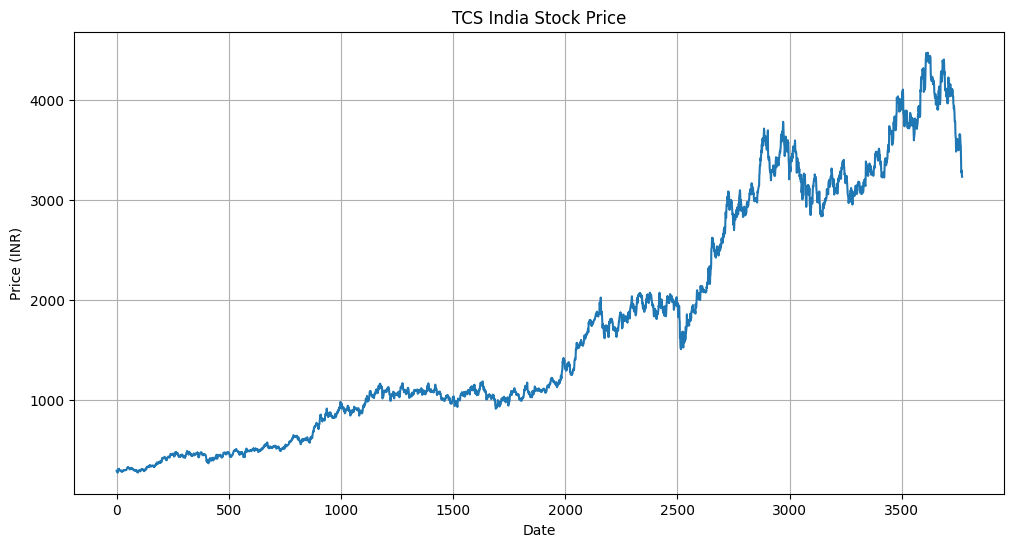

In [53]:
plt.figure(figsize=(12, 6))
plt.plot(df['Close'])
plt.title("TCS India Stock Price")
plt.xlabel("Date")
plt.ylabel("Price (INR)")
plt.grid(True)
plt.show()

In [54]:
df

Price,Close,High,Low,Open,Volume
Ticker,TCS.NS,TCS.NS,TCS.NS,TCS.NS,TCS.NS
0,294.361877,297.201129,293.343649,295.595469,1963682
1,294.440155,297.455641,292.364569,295.673770,2014488
2,287.782562,294.577198,287.058073,294.440116,3349176
3,279.773865,289.564383,278.442345,288.037053,6474892
4,274.056396,281.379715,272.764052,280.400662,6048178
...,...,...,...,...,...
3765,3299.399902,3399.649902,3295.500000,3362.600098,5317367
3766,3274.050049,3291.399902,3056.050049,3100.000000,6623955
3767,3292.949951,3349.000000,3255.300049,3302.050049,5557558


# Plotting moving averages of 100 day

---



In [55]:
ma100 = df.Close.rolling(100).mean()
ma100

Ticker,TCS.NS
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN
...,...
3765,3964.365398
3766,3955.777705
3767,3947.391809
3768,3939.005530


Text(0.5, 1.0, 'Graph Of Moving Averages Of 100 Days')

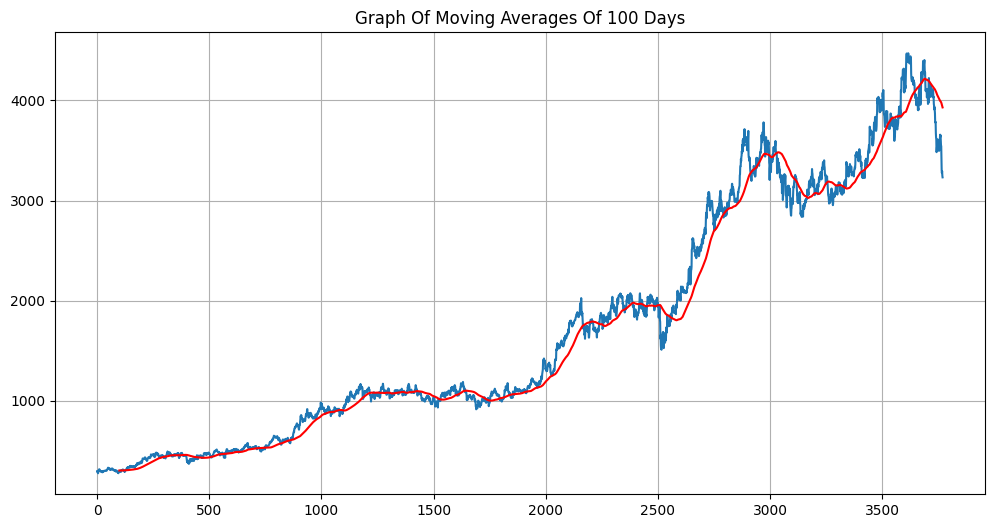

In [56]:
plt.figure(figsize = (12,6))
plt.plot(df.Close)
plt.plot(ma100, 'r')
plt.grid(True)
plt.title('Graph Of Moving Averages Of 100 Days')

# Defining 200 days moving averages and plotting comparision graph with 100 days moving averages

---



In [57]:
ma200 = df.Close.rolling(200).mean()
ma200

Ticker,TCS.NS
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN
...,...
3765,4054.641027
3766,4052.389818
3767,4050.303889
3768,4047.871104


Text(0.5, 1.0, 'Graph Of Moving Averages Of 200 Days')

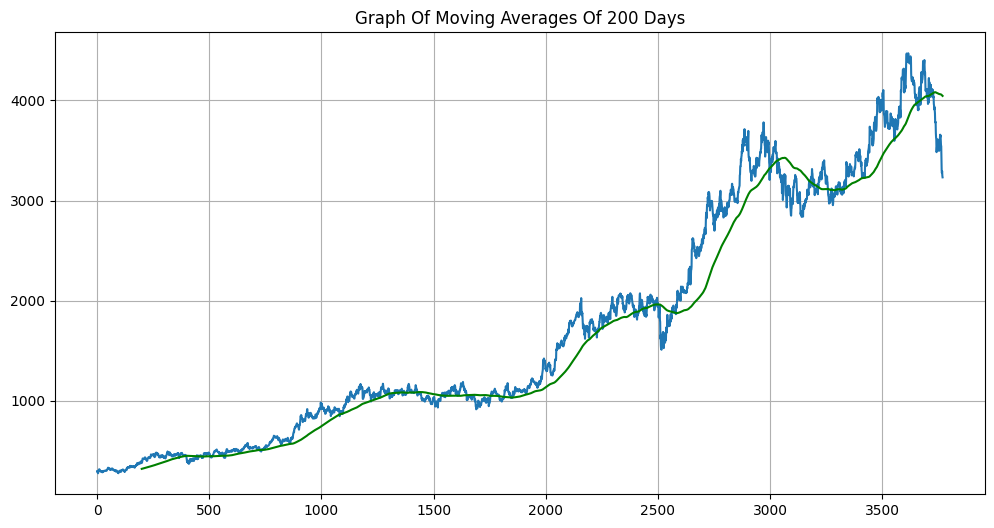

In [58]:
plt.figure(figsize = (12,6))
plt.plot(df.Close)
plt.plot(ma200, 'g')
plt.grid(True)
plt.title('Graph Of Moving Averages Of 200 Days')

Text(0.5, 1.0, 'Comparision Of 100 Days And 200 Days Moving Averages')

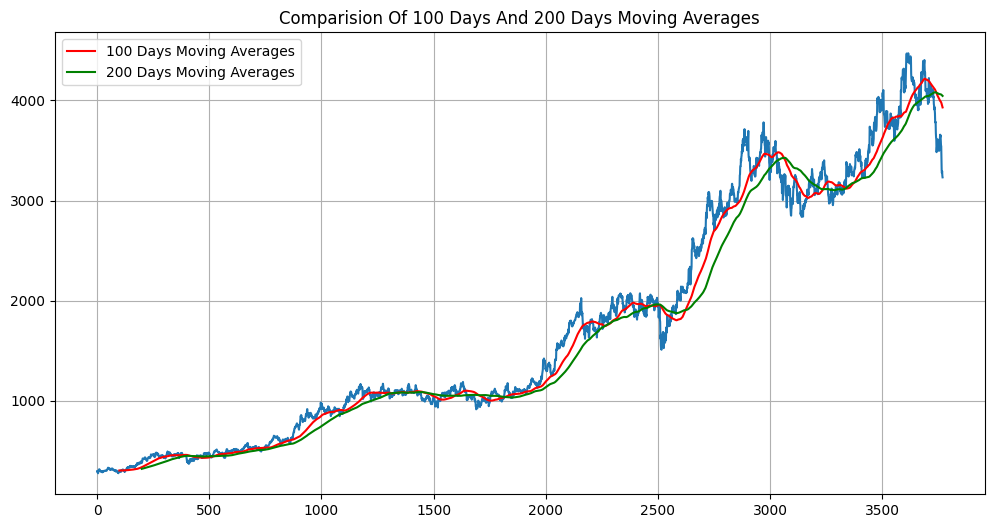

In [59]:
plt.figure(figsize = (12,6))
plt.plot(df.Close)
plt.plot(ma100, 'r',label="100 Days Moving Averages")
plt.plot(ma200, 'g',label="200 Days Moving Averages")
plt.legend()
plt.grid(True)
plt.title('Comparision Of 100 Days And 200 Days Moving Averages')

In [60]:
df.shape

(3770, 5)

# Spliting the dataset into training (70%) and testing (30%) set

In [61]:
# Splitting data into training and testing

train = pd.DataFrame(data[0:int(len(data)*0.70)])
test = pd.DataFrame(data[int(len(data)*0.70): int(len(data))])

print(train.shape)
print(test.shape)

(2639, 6)
(1131, 6)


In [62]:
train.head()

Price,Date,Close,High,Low,Open,Volume
Ticker,,TCS.NS,TCS.NS,TCS.NS,TCS.NS,TCS.NS
0,2010-01-04,294.361877,297.201129,293.343649,295.595469,1963682
1,2010-01-05,294.440155,297.455641,292.364569,295.673770,2014488
2,2010-01-06,287.782562,294.577198,287.058073,294.440116,3349176
3,2010-01-07,279.773865,289.564383,278.442345,288.037053,6474892
4,2010-01-08,274.056396,281.379715,272.764052,280.400662,6048178


In [63]:
test.head()

Price,Date,Close,High,Low,Open,Volume
Ticker,,TCS.NS,TCS.NS,TCS.NS,TCS.NS,TCS.NS
2639,2020-09-16,2319.303711,2323.566205,2295.489891,2306.284801,3074003
2640,2020-09-17,2280.339355,2312.585408,2270.749084,2297.991310,4828176
2641,2020-09-18,2270.101074,2316.894865,2257.591843,2302.625166,4183256
2642,2020-09-21,2284.370605,2321.064209,2272.185554,2284.092577,4598809
2643,2020-09-22,2337.789307,2367.487185,2277.606067,2302.624523,7499613


# Using MinMax scaler for normalization of the dataset

---



In [64]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0,1))

In [65]:
train_close = train.iloc[:, 4:5].values
test_close = test.iloc[:, 4:5].values

In [66]:
data_training_array = scaler.fit_transform(train_close)
data_training_array

array([[0.00978646],
       [0.00982498],
       [0.00921812],
       ...,
       [0.92686415],
       [0.95109092],
       [1.        ]])

In [67]:
x_train = []
y_train = []

for i in range(100, data_training_array.shape[0]):
    x_train.append(data_training_array[i-100: i])
    y_train.append(data_training_array[i, 0])

x_train, y_train = np.array(x_train), np.array(y_train)

In [68]:
x_train.shape

(2539, 100, 1)

# ML Model (LSTM)

---



In [69]:
from tensorflow.keras.layers import Dense, Dropout, LSTM
from tensorflow.keras.models import Sequential

In [70]:
model = Sequential()
model.add(LSTM(units = 50, activation = 'relu', return_sequences=True
              ,input_shape = (x_train.shape[1], 1)))
model.add(Dropout(0.2))


model.add(LSTM(units = 60, activation = 'relu', return_sequences=True))
model.add(Dropout(0.3))


model.add(LSTM(units = 80, activation = 'relu', return_sequences=True))
model.add(Dropout(0.4))


model.add(LSTM(units = 120, activation = 'relu'))
model.add(Dropout(0.5))

model.add(Dense(units = 1))

/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [71]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 100, 50)        │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 100, 50)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 100, 60)        │        26,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 100, 60)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_6 (LSTM)                   │ (None, 100, 80)        │        45,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 100, 80)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 120)            │        96,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           121 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 178,761 (698.29 KB)

 Trainable params: 178,761 (698.29 KB)

 Non-trainable params: 0 (0.00 B)

# Training the model

---



In [ ]:
import tensorflow as tf
model.compile(optimizer = 'adam', loss = 'mean_squared_error', metrics=[tf.keras.metrics.MeanAbsoluteError()])
model.fit(x_train, y_train,epochs = 100)

Epoch 1/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 18s 96ms/step - loss: 0.0705 - mean_absolute_error: 0.1851
Epoch 2/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - loss: 0.0073 - mean_absolute_error: 0.0583
Epoch 3/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 0.0067 - mean_absolute_error: 0.0569
Epoch 4/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - loss: 0.0058 - mean_absolute_error: 0.0528
Epoch 5/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - loss: 0.0054 - mean_absolute_error: 0.0518
Epoch 6/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - loss: 0.0048 - mean_absolute_error: 0.0478
Epoch 7/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 0.0050 - mean_absolute_error: 0.0483
Epoch 8/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 0.0042 - mean_absolute_error: 0.0455
Epoch 9/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - loss: 0.0037 - mean_absolute_error: 0.0424
Epoch 10/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 0.0041 - mean_absolute_error: 0.0435
Epoch 11/100
80/80 ━━━━━━━━━

In [ ]:
model.save('keras_model.h5')

In [ ]:
test_close.shape

(1131, 1)

In [ ]:
past_100_days = pd.DataFrame(train_close[-100:])

In [ ]:
test_df = pd.DataFrame(test_close)

**Defining the final dataset for testing by including last 100 coloums of the training dataset to get the prediction from the 1st column of the testing dataset.**

---


In [ ]:
final_df = pd.concat([past_100_days, test_df], ignore_index=True)

In [ ]:
final_df.head()

,0
0,1689.061729
1,1719.205768
2,1727.501799
3,1825.215310
4,1812.309651


In [ ]:
input_data = scaler.fit_transform(final_df)
input_data

array([[0.        ],
       [0.0107497 ],
       [0.01370815],
       ...,
       [0.5752094 ],
       [0.56041004],
       [0.57075176]])

In [ ]:
input_data.shape

(1231, 1)

# Testing the model

---



In [ ]:
x_test = []
y_test = []
for i in range(100, input_data.shape[0]):
   x_test.append(input_data[i-100: i])
   y_test.append(input_data[i, 0])

In [ ]:
x_test, y_test = np.array(x_test), np.array(y_test)
print(x_test.shape)
print(y_test.shape)

(1131, 100, 1)
(1131,)


# Making prediction and plotting the graph of predicted vs actual values

---



In [ ]:
# Making predictions

y_pred = model.predict(x_test)

36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step


In [ ]:
y_pred.shape

(1131, 1)

In [ ]:
y_test

array([0.22010855, 0.21715099, 0.21880348, ..., 0.5752094 , 0.56041004,
       0.57075176])

In [ ]:
y_pred

array([[0.21448095],
       [0.21727623],
       [0.2207967 ],
       ...,
       [0.6639167 ],
       [0.638044  ],
       [0.61382914]], dtype=float32)

In [ ]:
scaler.scale_

array([0.00035661])

In [ ]:
scale_factor = 1/0.00041967
y_pred = y_pred * scale_factor
y_test = y_test * scale_factor

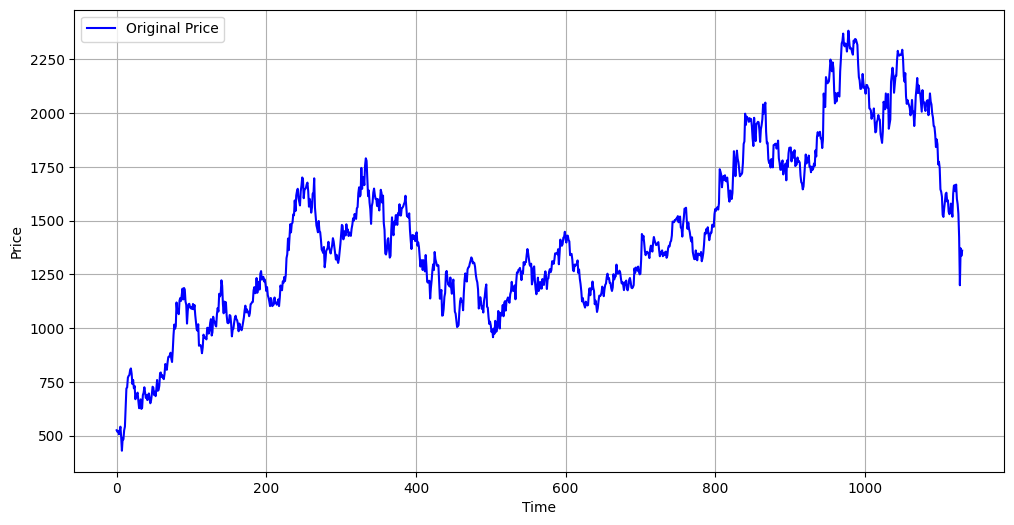

In [ ]:
plt.figure(figsize = (12,6))
plt.plot(y_test, 'b', label = "Original Price")
# plt.plot(y_pred, 'r', label = "Predicted Price")
plt.xlabel('Time')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.show()

# Model evaluation

Calculation of mean absolute error and accuracy

In [ ]:
from sklearn.metrics import mean_absolute_error ,mean_squared_error

mae = mean_absolute_error(y_test, y_pred)
mae_percentage = (mae / np.mean(y_test)) * 100
print("Mean absolute error on test set: {:.2f}%".format(mae_percentage))

# Accuracy as a percentage (based on MAE compared to average true values)
accuracy_percentage = (1 - (mae / np.mean(y_test))) * 100
print("Accuracy on test set: {:.2f}%".format(accuracy_percentage))


Mean absolute error on test set: 4.45%
Accuracy on test set: 95.55%


Calculation of R2 score

In [ ]:
from sklearn.metrics import r2_score

# Actual values
actual = y_test

# Predicted values
predicted = y_pred

# Calculate the R2 score
r2 = r2_score(actual, predicted)
print("R2 score:", r2)

R2 score: 0.9585848255922307


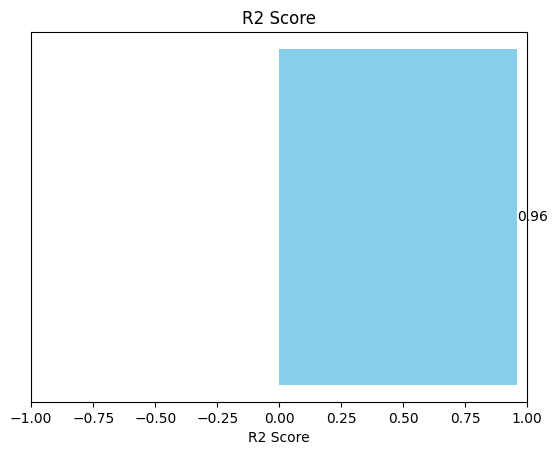

In [ ]:
# Plotting the R2 score
fig, ax = plt.subplots()
ax.barh(0, r2, color='skyblue')
ax.set_xlim([-1, 1])
ax.set_yticks([])
ax.set_xlabel('R2 Score')
ax.set_title('R2 Score')

# Adding the R2 score value on the bar
ax.text(r2, 0, f'{r2:.2f}', va='center', color='black')

plt.show()

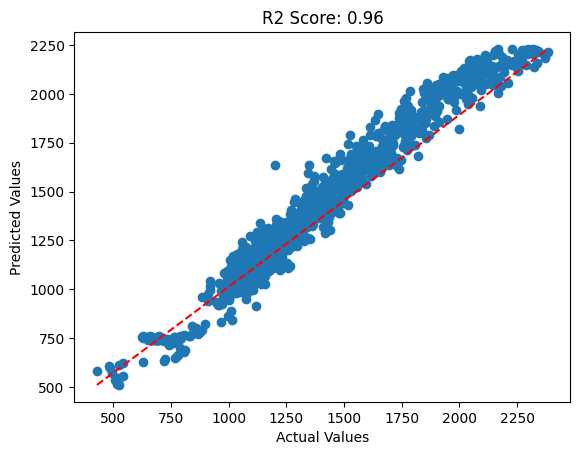

In [ ]:
plt.scatter(actual, predicted)
plt.plot([min(actual), max(actual)], [min(predicted), max(predicted)], 'r--')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title(f'R2 Score: {r2:.2f}')
plt.show()